<a href="https://colab.research.google.com/github/arpanghosal/ML_Classifier/blob/main/resnet_torch.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
import time
import copy
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split

In [ ]:
import torch, torchvision

In [ ]:
import torch.nn as nn
import torch.optim as optim
import torchvision.transforms as transforms
from torch.utils.data import Dataset, DataLoader, ConcatDataset

In [ ]:
train = pd.read_csv("./train.csv",dtype = np.float32)
test = pd.read_csv("./test.csv",dtype = np.float32)
submission = pd.read_csv("./sample_submission.csv")

In [ ]:
print("Train set:", train.shape, type(train))
print("Test set:", test.shape, type(test))

Train set: (16061, 785) <class 'pandas.core.frame.DataFrame'>
Test set: (6314, 784) <class 'pandas.core.frame.DataFrame'>


In [ ]:
label_dist = dict(train.label.value_counts())
len(label_dist)
print(label)

10

In [ ]:
print(dict(list(label_dist.items())[:3]))

{1.0: np.int64(1822), 7.0: np.int64(1655), 3.0: np.int64(1641)}


10 16061


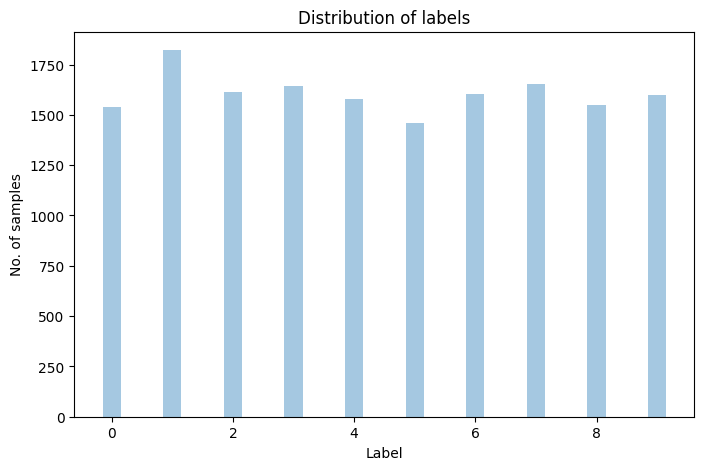

In [ ]:
number = label_dist.keys()
count = label_dist.values()
print(len(number), sum(count))

fig = plt.figure(figsize = (8, 5))

plt.bar(number, count, width=0.3, alpha=0.4)

plt.xlabel("Label")
plt.ylabel("No. of samples")
plt.title("Distribution of labels")
plt.show()


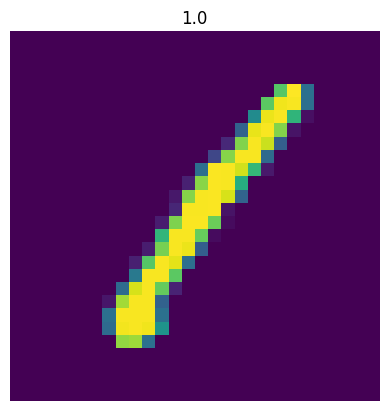

In [ ]:
plt.imshow(train.iloc[0, 1:].values.reshape(28,28))
plt.axis("off")
plt.title(str(train.iloc[0, 0]))
plt.show()


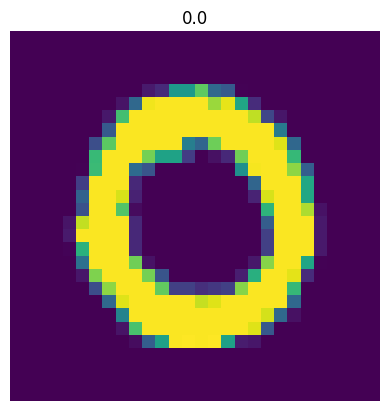

In [ ]:
plt.imshow(train.iloc[1, 1:].values.reshape(28,28))
plt.axis("off")
plt.title(str(train.iloc[1, 0]))
plt.show()


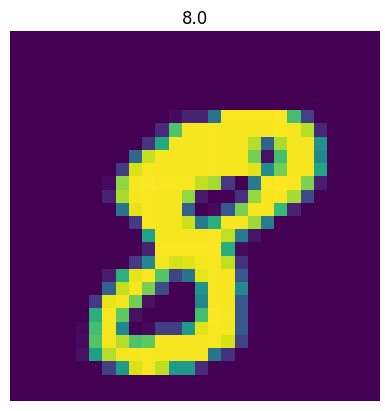

In [ ]:
plt.imshow(train.iloc[10, 1:].values.reshape(28,28))
plt.axis("off")
plt.title(str(train.iloc[10, 0]))
plt.show()

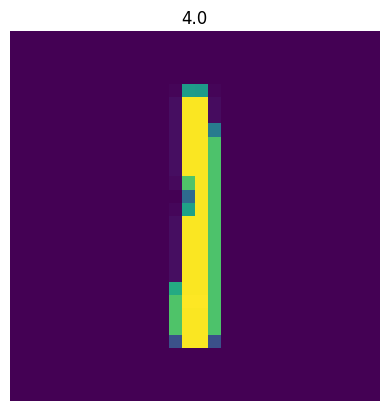

In [ ]:
plt.imshow(train.iloc[2, 1:].values.reshape(28,28))
plt.axis("off")
plt.title(str(train.iloc[3, 0]))
plt.show()

In [ ]:
labels = train.label.values
print(labels, len(labels))

[1. 0. 1. ... 4. 1. 6.] 16061


In [ ]:
data = train.iloc[:, 1:].values / 255 # Normalization
print(data.shape, data.dtype)

(16061, 784) float32


In [ ]:
labels = torch.from_numpy(labels).type(torch.LongTensor)

data = torch.from_numpy(data).view(data.shape[0], 1, 28, 28)

In [ ]:
print(labels.shape, labels.dtype)
print(labels.min(), labels.max())
print(labels.unique)

torch.Size([16061]) torch.int64
tensor(0) tensor(9)
<bound method Tensor.unique of tensor([1, 0, 1,  ..., 4, 1, 6])>


In [ ]:
print(data.shape, data.dtype)


torch.Size([16061, 1, 28, 28]) torch.float32


In [ ]:
train_data, val_data, train_labels, val_labels = train_test_split(data, labels, test_size = 0.3, random_state = 3)

In [ ]:
train_data.shape, val_data.shape, train_labels.shape, val_labels.shape

(torch.Size([11242, 1, 28, 28]),
 torch.Size([4819, 1, 28, 28]),
 torch.Size([11242]),
 torch.Size([4819]))

In [ ]:
#TensorDataset class does not support transformations by default.
#We need to create a custom dataset class to add augmentations and use the data in DataLoaders¶

In [ ]:
class CustomTensorDataset(Dataset):

    def __init__(self, data, labels=None, transform=None):
        self.data = data
        self.labels = labels
        self.transform = transform

        print("Data shape:", data.shape)
        if labels is not None:
            print("Labels shape:", labels.shape)

    def __getitem__(self, index):
        x = self.data[index]

        if self.transform:
            x = self.transform(x)

        if self.labels is None:
            return x

        return x, self.labels[index]

    def __len__(self):
        return self.data.size(0)

In [ ]:
 #transform our data to images, apply transformations and transform it back to tensors

In [ ]:
transform = transforms.Compose([
    transforms.ToPILImage(),
    transforms.RandomAffine(degrees=20, scale=(1.1, 1.1)),
    transforms.RandomCrop((28, 28), padding=2, pad_if_needed=True, fill=0, padding_mode='constant'),
    transforms.ToTensor()
])

In [ ]:
sample = CustomTensorDataset(train_data[:4], train_labels[:4])

Data shape: torch.Size([4, 1, 28, 28])
Labels shape: torch.Size([4])


In [ ]:
sample_aug = CustomTensorDataset(train_data[:4], train_labels[:4], transform=transform)

Data shape: torch.Size([4, 1, 28, 28])
Labels shape: torch.Size([4])


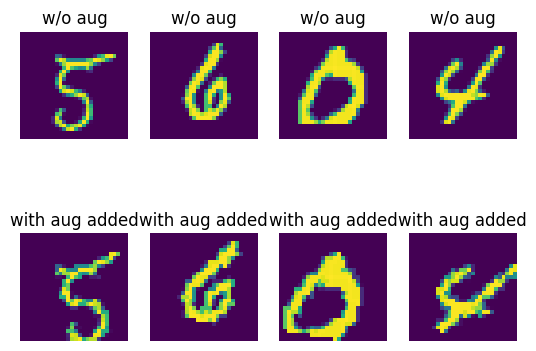

In [ ]:
fig, axs = plt.subplots(2, 4)

for i, item in enumerate(zip(sample, sample_aug)):

    im = item[0][0].squeeze().numpy()
    im_aug = item[1][0].squeeze().numpy()

    axs[0, i].imshow(im)
    axs[0, i].set_title("w/o aug")
    axs[0, i].axis('off')

    axs[1, i].imshow(im_aug)
    axs[1, i].set_title("with aug added")
    axs[1, i].axis('off')

In [ ]:
#create training and validation sets
trainset = ConcatDataset([
    CustomTensorDataset(train_data, train_labels),
    CustomTensorDataset(train_data, train_labels, transform=transform)
])
valset = CustomTensorDataset(val_data, val_labels)

Data shape: torch.Size([11242, 1, 28, 28])
Labels shape: torch.Size([11242])
Data shape: torch.Size([11242, 1, 28, 28])
Labels shape: torch.Size([11242])
Data shape: torch.Size([4819, 1, 28, 28])
Labels shape: torch.Size([4819])


In [ ]:
train_loader = DataLoader(trainset, batch_size=32, shuffle=True) # batching and shuffling

In [ ]:
val_loader = DataLoader(valset, batch_size=32, shuffle=False) # batching and shuffling

In [ ]:
device = torch.device("cuda:0" if torch.cuda.is_available() else "cpu")
device

device(type='cuda', index=0)

In [ ]:
print(device)

cuda:0


## Model

In [ ]:
class Block(nn.Module):

    def __init__(self, in_channels, out_channels, identity_downsample=None, stride=1):
        super(Block, self).__init__()
        self.conv1 = nn.Conv2d(in_channels, out_channels, kernel_size=3, stride=stride, padding=1)
        self.bn1 = nn.BatchNorm2d(out_channels)
        self.conv2 = nn.Conv2d(out_channels, out_channels, kernel_size=3, stride=1, padding=1)
        self.bn2 = nn.BatchNorm2d(out_channels)
        self.relu = nn.ReLU()
        self.identity_downsample = identity_downsample

    def forward(self, x):
        identity = x
        x = self.conv1(x)
        x = self.bn1(x)
        x = self.relu(x)
        x = self.conv2(x)
        x = self.bn2(x)
        if self.identity_downsample is not None:
            identity = self.identity_downsample(identity)
        x += identity
        x = self.relu(x)
        return x

In [ ]:
class ResNet_18(nn.Module):

    def __init__(self, image_channels, num_classes):

        super(ResNet_18, self).__init__()
        self.in_channels = 64
        self.conv1 = nn.Conv2d(image_channels, 64, kernel_size=7, stride=2, padding=3)
        self.bn1 = nn.BatchNorm2d(64)
        self.relu = nn.ReLU()
        self.maxpool = nn.MaxPool2d(kernel_size=3, stride=2, padding=1)

        #resnet layers
        self.layer1 = self.__make_layer(64, 64, stride=1)
        self.layer2 = self.__make_layer(64, 128, stride=2)
        self.layer3 = self.__make_layer(128, 256, stride=2)
        self.layer4 = self.__make_layer(256, 512, stride=2)

        self.avgpool = nn.AdaptiveAvgPool2d((1, 1))
        self.fc = nn.Linear(512, num_classes)

    def __make_layer(self, in_channels, out_channels, stride):

        identity_downsample = None
        if stride != 1:
            identity_downsample = self.identity_downsample(in_channels, out_channels)

        return nn.Sequential(
            Block(in_channels, out_channels, identity_downsample=identity_downsample, stride=stride),
            Block(out_channels, out_channels)
        )

    def forward(self, x):

        x = self.conv1(x)
        x = self.bn1(x)
        x = self.relu(x)
        x = self.maxpool(x)

        x = self.layer1(x)
        x = self.layer2(x)
        x = self.layer3(x)
        x = self.layer4(x)

        x = self.avgpool(x)
        x = x.view(x.shape[0], -1)
        x = self.fc(x)
        return x

    def identity_downsample(self, in_channels, out_channels):

        return nn.Sequential(
            nn.Conv2d(in_channels, out_channels, kernel_size=3, stride=2, padding=1),
            nn.BatchNorm2d(out_channels)
        )

In [ ]:
model = ResNet_18(1, 10)

In [ ]:
#count trainable parameters of the model
def count_parameters(model):
    return sum(p.numel() for p in model.parameters())

count_parameters(model)


12556426

In [ ]:
def count_parameters(model):
    return sum(p.numel() for p in model.parameters() if p.requires_grad)

count_parameters(model)

12556426

In [ ]:
model.to(device)
next(model.parameters()).is_cuda

True

In [ ]:
epochs = 5
criterion = nn.CrossEntropyLoss()
optimizer = optim.Adam(model.parameters(), lr=0.0001, weight_decay=1e-4)
lr_scheduler = optim.lr_scheduler.ReduceLROnPlateau(optimizer, patience=5,)

## Running batch epochs

In [ ]:
def train_model(model, dataloaders, criterion, optimizer, num_epochs=50, is_inception=False):

    since = time.time()
    val_acc_history = []
    best_model_wts = copy.deepcopy(model.state_dict())
    best_acc = 0.0

    for epoch in range(num_epochs):
        print('Epoch {}/{}'.format(epoch, num_epochs - 1))
        print('-' * 10)

        for phase in ['train', 'val']: # Each epoch has a training and validation phase
            if phase == 'train':
                model.train()  # Set model to training mode
            else:
                model.eval()   # Set model to evaluate mode

            running_loss = 0.0
            running_corrects = 0

            for inputs, labels in dataloaders[phase]: # Iterate over data

                inputs = transforms.functional.resize(inputs, (112, 112))
                inputs = inputs.to(device)

                labels = labels.to(device)

                optimizer.zero_grad() # Zero the parameter gradients

                with torch.set_grad_enabled(phase == 'train'): # Forward. Track history if only in train

                    outputs = model(inputs)
                    loss = criterion(outputs, labels)
                    _, preds = torch.max(outputs, 1)

                    if phase == 'train': # Backward + optimize only if in training phase
                        loss.backward()
                        optimizer.step()

                # Statistics
                running_loss += loss.item() * inputs.size(0)
                running_corrects += torch.sum(preds == labels.data)

            epoch_loss = running_loss / len(dataloaders[phase].dataset)

            if phase == 'val': # Adjust learning rate based on val loss
                lr_scheduler.step(epoch_loss)

            epoch_acc = running_corrects.double() / len(dataloaders[phase].dataset)

            print('{} Loss: {:.4f} Acc: {:.4f}'.format(phase, epoch_loss, epoch_acc))

            # deep copy the model
            if phase == 'val' and epoch_acc > best_acc:
                best_acc = epoch_acc
                best_model_wts = copy.deepcopy(model.state_dict())
            if phase == 'val':
                val_acc_history.append(epoch_acc)

        print()

    time_elapsed = time.time() - since
    print('Training complete in {:.0f}m {:.0f}s'.format(time_elapsed // 60, time_elapsed % 60))
    print('Best val Acc: {:4f}'.format(best_acc))

    # load best model weights
    model.load_state_dict(best_model_wts)
    return model, val_acc_history




In [ ]:
# Debug -> for testset None
# in __init__
print("Data shape:", data.shape)
if labels is not None:
    print("Labels shape:", labels.shape)

Data shape: torch.Size([16061, 1, 28, 28])
Labels shape: torch.Size([16061])


In [ ]:
model, _ = train_model(model, {"train": train_loader, "val": val_loader}, criterion, optimizer, epochs)


Epoch 0/4
----------


/usr/local/lib/python3.13/dist-packages/torchvision/transforms/functional.py:282: RuntimeWarning: invalid value encountered in cast
  npimg = (npimg * 255).astype(np.uint8)


train Loss: nan Acc: 0.4619
val Loss: nan Acc: 0.0992

Epoch 1/4
----------
train Loss: nan Acc: 0.0943
val Loss: nan Acc: 0.0992

Epoch 2/4
----------
train Loss: nan Acc: 0.0943
val Loss: nan Acc: 0.0992

Epoch 3/4
----------
train Loss: nan Acc: 0.0943
val Loss: nan Acc: 0.0992

Epoch 4/4
----------
train Loss: nan Acc: 0.0943
val Loss: nan Acc: 0.0992

Training complete in 1m 30s
Best val Acc: 0.099191


In [ ]:
#prepare test set for the model
test = pd.read_csv("test.csv")   # your original load line

#test_np = test.values
#test_t = torch.from_numpy(test_np / 255).float().view(-1, 1, 28, 28)


test = test.values / 255
test = torch.from_numpy(test).view(test.shape[0], 1, 28, 28)

In [ ]:

#prepare a dataloader with the test set
testset = CustomTensorDataset(test, None)
test_loader = DataLoader(testset, batch_size=32, shuffle=False)



Data shape: torch.Size([28000, 1, 28, 28])


In [ ]:
#turn on the evaluation mode and make predictions batch by batch (otherwise it lack gpu memory)
#to use predictions for the submission we first need to transfer to the cpu
model.eval()
labels = []
with torch.no_grad():
    for inputs in test_loader:
        inputs = inputs.float()
        inputs = transforms.functional.resize(inputs, (112, 112))
        inputs = inputs.to(device)
        outputs = model(inputs)
        _, predictions = torch.max(outputs, 1)
        labels.extend(predictions.cpu().numpy())

In [ ]:
submission['Label'] = labels
submission.to_csv('submission.csv', index=False)

In [ ]:
from sklearn.metrics import accuracy_score, confusion_matrix

def evaluate(model, loader):
    model.eval()
    preds, truth = [], []
    with torch.no_grad():
        for x, y in loader:
            x = transforms.functional.resize(x.float(), (112, 112)).to(device)
            out = model(x)
            preds.extend(out.argmax(1).cpu().numpy())
            truth.extend(y.numpy())
    return np.array(truth), np.array(preds)

truth, preds = evaluate(model, val_loader)
print("Accuracy:", accuracy_score(truth, preds))
print(confusion_matrix(truth, preds))

Accuracy: 0.09919070346544927
[[478   0   0   0   0   0   0   0   0   0]
 [508   0   0   0   0   0   0   0   0   0]
 [485   0   0   0   0   0   0   0   0   0]
 [510   0   0   0   0   0   0   0   0   0]
 [474   0   0   0   0   0   0   0   0   0]
 [467   0   0   0   0   0   0   0   0   0]
 [447   0   0   0   0   0   0   0   0   0]
 [506   0   0   0   0   0   0   0   0   0]
 [490   0   0   0   0   0   0   0   0   0]
 [454   0   0   0   0   0   0   0   0   0]]


In [ ]:
X = torch.from_numpy(train.iloc[:, 1:].values / 255).float().view(-1, 1, 28, 28)
y = torch.from_numpy(train.iloc[:, 0].values).long()

X_tr, X_val, y_tr, y_val = train_test_split(X, y, test_size=0.2, random_state=42, stratify=y)
val_loader = DataLoader(CustomTensorDataset(X_val, y_val), batch_size=32, shuffle=False)

Data shape: torch.Size([3213, 1, 28, 28])
Labels shape: torch.Size([3213])
